# From delivered tables to the adaptation corpus

The inputs used by training and evaluation: every processed credit table with its size, predictors, missingness, target and held-out partition (one figure), the LGD target shapes that motivate the window objective, and how a full pass would redistribute optimizer updates across tables (the E8 question). These are local corpus measurements, separate from training outcomes.

The corpus defines the population to which the CPT study applies; related source populations and local preprocessing limit broader generalisation.

In [1]:
%matplotlib inline
import sys
from pathlib import Path
REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'pyproject.toml').is_file())
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))
from src.visualize import style, campaign as cp
from src.visualize import corpus as cv
from src.visualize.figures import FigureSaver
from src.data.dataset_names import display_frame
style.apply()
sink = FigureSaver('general/02_processed_data')
report = cp.NotebookReport('From delivered tables to the adaptation corpus', sink=sink)

## 1. Processed inventory and preprocessing footprint

Available tables after the registered cleaning rules, and registered versus processed shapes. Registration already contains dataset-specific corrections, so the comparison is against that registered shape, not the untouched download.

In [2]:
data = cv.processed_inventory()
report.table('Processed tables', data[['track', 'dataset_id', 'rows', 'features', 'missing', 'minority_class_ratio', 'target_mean', 'target_std']])
report.table('Registered and processed shapes', data[['track', 'dataset_id', 'raw_rows', 'post_rows', 'raw_features', 'post_features']])
report.add('1. Processed inventory and preprocessing footprint', cv.inventory_summary(data, 'Processed'))

,track,dataset_id,rows,features,missing,minority_class_ratio,target_mean,target_std
0,pd,GMSC,150000,10,0.022437,0.066840,NaN,NaN
1,pd,Taiwan Credit Card,30000,23,0.000000,0.221200,NaN,NaN
2,pd,Vehicle Loan,233154,33,0.000996,0.217071,NaN,NaN
3,pd,LendingClub,9578,13,0.000000,0.160054,NaN,NaN
4,pd,Myhom,7000,8,0.004375,0.400000,NaN,NaN
5,pd,Hackerearth,532428,36,0.067109,0.236327,NaN,NaN
6,pd,Cobranded,80000,47,0.188361,0.246213,NaN,NaN
7,pd,German Credit,999,20,0.000000,0.300300,NaN,NaN
8,pd,PropPD1,100000,16,0.060931,0.226390,NaN,NaN
9,pd,Thomas,1225,14,0.000000,0.263673,NaN,NaN


,track,dataset_id,raw_rows,post_rows,raw_features,post_features
0,pd,GMSC,150000,150000,10,10
1,pd,Taiwan Credit Card,30000,30000,23,23
2,pd,Vehicle Loan,233154,233154,33,33
3,pd,LendingClub,9578,9578,13,13
4,pd,Myhom,7000,7000,8,8
5,pd,Hackerearth,532428,532428,37,36
6,pd,Cobranded,80000,80000,47,47
7,pd,German Credit,999,999,20,20
8,pd,PropPD1,100000,100000,16,16
9,pd,Thomas,1225,1225,14,14


## 2. The corpus at a glance

Each table once: rows and predictors (log axes, spanning orders of magnitude), missing predictor cells, the default rate (PD) or mean loss rate (LGD), and the partition in which it is held out. The four dataset partitions are distinct from the five row-level outer folds of the final evaluation; every table is held out from continued pretraining exactly once.

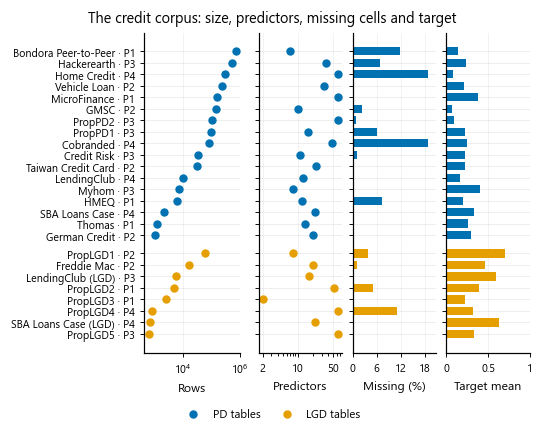

Every processed credit table, PD (17) above LGD (8), each block ordered by decreasing row count; P1–P4 is the dataset partition in which the table is held out from continued pretraining. Rows and predictors use logarithmic axes; missing predictor cells exclude the target; the last panel shows the minority-class (default) rate for PD and the mean loss rate for LGD, both on a zero-based axis.

,track,dataset,partition
0,pd,Thomas,1
1,pd,HMEQ,1
2,pd,MicroFinance,1
3,pd,Bondora Peer-to-Peer,1
4,pd,GMSC,2
5,pd,Taiwan Credit Card,2
6,pd,Vehicle Loan,2
7,pd,German Credit,2
8,pd,Myhom,3
9,pd,Hackerearth,3


In [3]:
partitions = cv.partition_table()
cp.show(sink, cv.plot_corpus_overview(data, partitions))
report.table('Dataset partition membership', partitions.rename(columns={'fold': 'partition'}))
report.add('2. The corpus at a glance', partitions.groupby(['track', 'fold']).size().rename('held_out_tables').to_string())

## 3. LGD target distributions

Loss rates pile up at 0 and 1 with a spread interior, which is why LGD is scored with R², normalised RMSE and distributional metrics and why TabPFN LGD trains with the window objective.

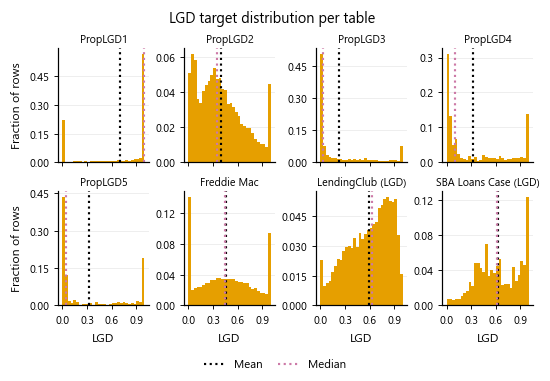

Processed LGD target of each of the 8 LGD tables: 30-bin histograms of the fraction of rows, with dotted lines at the table's mean and median. Values follow the registered preprocessing, including the [0, 1] clip; tables are not pooled and vertical scales differ between panels.

In [4]:
cp.show(sink, cv.plot_lgd_distributions())
report.add('3. LGD target distributions', 'Histograms describe the processed targets; no additional clipping is applied by the plot.')

## 4. Optimizer-update shares: one sample versus full pass

The reference visits every training table equally (one sampled episode per visit); the full pass of E8 gives one update per disjoint chunk, so large tables receive most updates. The multiplier beside each table is its full-pass share divided by its equal-visit share.

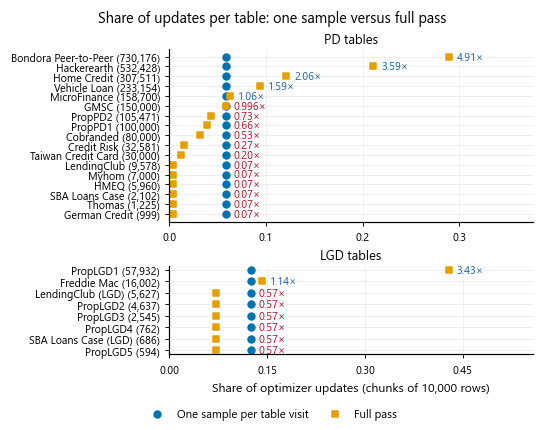

Planned share of optimizer updates per credit table if every processed table of the task were in the corpus: one sampled episode per table visit (circles, equal shares) versus a full pass over disjoint chunks of 10,000 context-plus-query rows (squares, one update per chunk). Labels give the table's rows and the full-pass share divided by the one-sample share (blue above one, red below; colour does not mean better or worse). Illustration only: runs train on three of four partitions, TabPFN v3 and TabICLv2 use 26,000-row episodes, and a run stops at its update budget.

In [5]:
exposure = cv.planned_exposure(data)
cp.show(sink, cv.plot_exposure(exposure))
report.add('4. Optimizer-update shares: one sample versus full pass', 'Illustration only: a 10,000-row chunk, all processed tables and no skipped updates. Actual runs use base-specific caps and training partitions.')

## 5. Quality flags

Flags are descriptive prompts for inspection, not unrecorded exclusion rules.

In [6]:
from src.data.exploration import find_anomalous_datasets
anomalies = display_frame(find_anomalous_datasets())
report.table('Quality flags', anomalies)
report.add('5. Quality flags', 'No configured anomaly flags.' if anomalies.empty else 'Flagged datasets remain in the registered corpus unless an explicit design change is made.')

""


## Summary

Every displayed table and figure, in section order.

In [7]:
print(report.summary(sink))

From delivered tables to the adaptation corpus

1. Processed inventory and preprocessing footprint
Processed: 25/25 registered datasets available.
       datasets     rows  min_rows  max_rows  max_features
track                                                     
lgd           8    88785       594     57932            64
pd           17  2486885       999    730176            64

Table: Processed tables
CSV (first column: row index)
row,track,dataset_id,rows,features,missing,minority_class_ratio,target_mean,target_std
0,pd,GMSC,150000,10,0.022436667,0.06684,unavailable,unavailable
1,pd,Taiwan Credit Card,30000,23,0,0.2212,unavailable,unavailable
2,pd,Vehicle Loan,233154,33,0.00099570033,0.21707112,unavailable,unavailable
3,pd,LendingClub,9578,13,0,0.16005429,unavailable,unavailable
4,pd,Myhom,7000,8,0.004375,0.4,unavailable,unavailable
5,pd,Hackerearth,532428,36,0.06710897,0.23632679,unavailable,unavailable
6,pd,Cobranded,80000,47,0.1883609,0.2462125,unavailable,unavailable
7,pd,Germa